# Model Training and Comparison

Notebook này là **thử nghiệm ban đầu** của bước xây dựng mô hình: so sánh 6 mô hình trên **một lần chia dữ liệu** (huấn luyện trước 2024, kiểm thử 2024–2026). Kết quả ở đây là cơ sở để thiết kế đánh giá đầy đủ ở Notebook 7 và 8.
- **RQ2:** so sánh 6 mô hình dự báo nhu cầu **tuần tới** cho từng khu phố, kiểm tra theo nhiều mốc thời gian và sang khu phố mới; những yếu tố nào thực sự đóng góp vào dự báo (SHAP và thử bỏ từng nhóm yếu tố).
- **RQ3:** tái huấn luyện định kỳ có giúp mô hình thích ứng tốt hơn không.
- **RQ4:** độ tin cậy của khoảng dự báo và cảnh báo tuần nguy cơ cao.

**Dữ liệu đầu vào:** `SF_Tree_Weekly_Features.csv` (Notebook 3) — đã có sẵn đặc trưng trễ, trung bình 4 tuần và biến mục tiêu `y_next` (số yêu cầu tuần tới).

**6 mô hình:**

| Nhóm | Mô hình | Cách dự báo tuần tới |
|---|---|---|
| Mốc đơn giản | Lặp lại tuần trước | = số yêu cầu tuần hiện tại (`n`) |
| Mốc đơn giản | Trung bình 4 tuần | = trung bình 4 tuần gần nhất (`n_ma4`) |
| Hồi quy tuyến tính | Ridge | học từ các đặc trưng |
| Mô hình cây | Random Forest | học từ các đặc trưng |
| Cây tăng cường | LightGBM | học từ các đặc trưng |
| Mô hình nền zero-shot | Chronos-Bolt | chỉ dùng chuỗi lịch sử số yêu cầu, **không huấn luyện lại** |

**Chỉ số đánh giá:** MAE (sai số tuyệt đối trung bình, đơn vị: số yêu cầu/tuần), RMSE, và mức cải thiện MAE so với mốc "Lặp lại tuần trước".

## **1. Khởi tạo và nạp dữ liệu**

In [1]:
# Nếu thiếu thư viện, chạy 1 lần: pip install scikit-learn lightgbm shap chronos-forecasting
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb

import warnings
warnings.filterwarnings("ignore")
sns.set_style("ticks")
os.makedirs("../Outputs/figures", exist_ok=True)
os.makedirs("../Outputs/tables", exist_ok=True)
MAU = "#2E6DA4"

feat_all = pd.read_csv("../Data/processed/SF_Tree_Weekly_Features.csv", parse_dates=["week_start"])
feat_all = feat_all.sort_values(["nbhd", "week_start"]).reset_index(drop=True)
feat_all["nbhd_code"] = feat_all["nbhd"].astype("category").cat.codes   # mã số khu phố cho mô hình

print(feat_all.shape)

(25174, 34)


In [2]:
# Các đặc trưng đưa vào mô hình, chia theo nhóm (dùng lại ở phần RQ4)
NHOM_DAC_TRUNG = {
    "Lịch sử nhu cầu":    ["n", "n_lag1", "n_lag2", "n_lag52", "n_ma4"],
    "Giấy phép thi công": ["permits_active"],
    "Thời tiết":          ["PRCP", "AWND", "TMAX"],
    "Đặc điểm cây":       ["so_cay", "dbh_tb", "tuoi_cay_tb"],
    "Lịch (tháng)":       ["month"],
    "Khu phố":            ["nbhd_code"],
}
FEATURES = [c for cols in NHOM_DAC_TRUNG.values() for c in cols]
TARGET = "y_next"

# Bỏ các dòng thiếu đặc trưng trễ (52 tuần đầu, chưa có n_lag52) và tuần cuối (chưa có y_next)
n0 = len(feat_all)
feat = feat_all.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print(f"Đã bỏ {n0 - len(feat):,} dòng thiếu đặc trưng hoặc thiếu biến mục tiêu")
print(f"Còn lại: {len(feat):,} dòng, từ {feat['week_start'].min().date()} đến {feat['week_start'].max().date()}")

Đã bỏ 2,173 dòng thiếu đặc trưng hoặc thiếu biến mục tiêu
Còn lại: 23,001 dòng, từ 2016-01-04 đến 2026-09-28


## **2. Chia tập huấn luyện và kiểm thử theo thời gian**

- **Huấn luyện:** các tuần trước 2024; **kiểm thử:** từ tuần đầu tiên của 2024 đến hết dữ liệu.
- Mỗi dòng dự báo cho **tuần sau**, nên tuần cuối cùng của tập huấn luyện được bỏ bớt 1 tuần để biến mục tiêu của tập huấn luyện không rơi vào thời gian kiểm thử (tránh rò rỉ tương lai).

In [3]:
TEST_START = pd.Timestamp("2024-01-01")

train = feat[feat["week_start"] < TEST_START - pd.Timedelta(days=7)].copy()
test = feat[feat["week_start"] >= TEST_START].copy()

print(f"Huấn luyện: {len(train):,} dòng ({train['week_start'].min().date()} đến {train['week_start'].max().date()})")
print(f"Kiểm thử  : {len(test):,} dòng ({test['week_start'].min().date()} đến {test['week_start'].max().date()}), {test['week_start'].nunique()} tuần")

Huấn luyện: 17,056 dòng (2016-01-04 đến 2023-12-18)
Kiểm thử  : 5,904 dòng (2024-01-01 đến 2026-09-28), 144 tuần


## **3. Huấn luyện và so sánh 6 mô hình — trả lời RQ2**

In [4]:
def make_model(name, cols, seed=0):
    """Tạo mô hình theo tên; cols là danh sách đặc trưng sử dụng."""
    if name == "Ridge":
        cat = [c for c in ["nbhd_code", "month"] if c in cols]   # biến phân loại -> mã hoá one-hot
        num = [c for c in cols if c not in cat]
        pre = ColumnTransformer([("num", StandardScaler(), num),
                                 ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
        return make_pipeline(pre, Ridge(alpha=1.0))
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5,
                                     n_jobs=-1, random_state=seed)
    if name == "LightGBM":
        # objective="poisson": phù hợp với dữ liệu đếm (số yêu cầu không âm, lệch phải)
        return lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                 objective="poisson", random_state=seed, verbosity=-1)


def fit_predict(name, tr, te, cols=FEATURES, seed=0):
    model = make_model(name, cols, seed)
    model.fit(tr[cols], tr[TARGET])
    pred = np.clip(model.predict(te[cols]), 0, None)   # số yêu cầu không thể âm
    return pred, model

In [5]:
# 2 mốc đơn giản: không cần huấn luyện
test["pred_Lặp lại tuần trước"] = test["n"]
test["pred_Trung bình 4 tuần"] = test["n_ma4"]

# 3 mô hình học máy: Random Forest và LightGBM chạy 3 seed để kiểm tra độ ổn định
SEEDS = [0, 1, 2]
seed_rows = []
for name in ["Ridge", "Random Forest", "LightGBM"]:
    seeds = [0] if name == "Ridge" else SEEDS          # Ridge không có yếu tố ngẫu nhiên
    preds = []
    for s in seeds:
        pred, _ = fit_predict(name, train, test, seed=s)
        preds.append(pred)
        seed_rows.append({"mo_hinh": name, "seed": s, "MAE": mean_absolute_error(test[TARGET], pred)})
    test[f"pred_{name}"] = np.mean(preds, axis=0)
    print(f"Đã huấn luyện xong {name}")

seed_df = pd.DataFrame(seed_rows)
seed_df.groupby("mo_hinh")["MAE"].agg(["mean", "std"]).round(4)

Đã huấn luyện xong Ridge
Đã huấn luyện xong Random Forest
Đã huấn luyện xong LightGBM


,mean,std
mo_hinh,,
LightGBM,2.7683,0.0088
Random Forest,2.7439,0.0015
Ridge,2.6949,NaN


### Mô hình nền zero-shot: Chronos-Bolt

Chronos-Bolt (Amazon) là mô hình nền chuỗi thời gian đã được huấn luyện sẵn trên rất nhiều chuỗi khác nhau. Mô hình **không được huấn luyện lại** trên dữ liệu San Francisco: mỗi tuần kiểm thử, đưa vào chuỗi lịch sử số yêu cầu của từng khu phố (đến hết tuần hiện tại) và lấy dự báo cho tuần tới. Dùng **trung vị** của dự báo làm giá trị dự báo.

Lần chạy đầu sẽ tải mô hình (khoảng 200 MB) từ Hugging Face.

In [6]:
import torch
from chronos import BaseChronosPipeline

chronos = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small",
                                              device_map="cpu", torch_dtype=torch.float32)

# Chuỗi lịch sử đầy đủ của từng khu phố (dùng bảng feat_all để có cả các tuần đầu năm 2015)
series = {nb: g.set_index("week_start")["n"].astype(float) for nb, g in feat_all.groupby("nbhd")}

rows = []
test_weeks = sorted(test["week_start"].unique())
for i, w in enumerate(test_weeks):
    nbs = sorted(test.loc[test["week_start"] == w, "nbhd"].unique())
    contexts = [torch.tensor(series[nb].loc[:w].values[-512:], dtype=torch.float32) for nb in nbs]
    q, _ = chronos.predict_quantiles(contexts, prediction_length=1, quantile_levels=[0.1, 0.5, 0.9])
    for nb, qq in zip(nbs, q[:, 0, :].numpy()):
        rows.append({"nbhd": nb, "week_start": w, "pred_Chronos-Bolt (zero-shot)": max(qq[1], 0)})
    if (i + 1) % 25 == 0:
        print(f"Đã dự báo {i + 1}/{len(test_weeks)} tuần")

test = test.merge(pd.DataFrame(rows), on=["nbhd", "week_start"], how="left")
print("Xong Chronos-Bolt.")

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Đã dự báo 25/144 tuần
Đã dự báo 50/144 tuần
Đã dự báo 75/144 tuần
Đã dự báo 100/144 tuần
Đã dự báo 125/144 tuần
Xong Chronos-Bolt.


In [7]:
MODELS = ["Lặp lại tuần trước", "Trung bình 4 tuần", "Ridge", "Random Forest", "LightGBM",
          "Chronos-Bolt (zero-shot)"]

mae_base = mean_absolute_error(test[TARGET], test["pred_Lặp lại tuần trước"])
results = pd.DataFrame([{
    "mo_hinh": m,
    "MAE": mean_absolute_error(test[TARGET], test[f"pred_{m}"]),
    "RMSE": np.sqrt(mean_squared_error(test[TARGET], test[f"pred_{m}"])),
} for m in MODELS])
results["cai_thien_so_voi_lap_lai_%"] = (1 - results["MAE"] / mae_base) * 100
results = results.sort_values("MAE").reset_index(drop=True).round(3)
results

,mo_hinh,MAE,RMSE,cai_thien_so_voi_lap_lai_%
0,Chronos-Bolt (zero-shot),2.598,4.370,20.188
1,Ridge,2.695,4.497,17.215
2,Random Forest,2.743,4.601,15.747
3,LightGBM,2.764,4.657,15.093
4,Trung bình 4 tuần,2.810,4.537,13.671
5,Lặp lại tuần trước,3.255,5.179,0.000


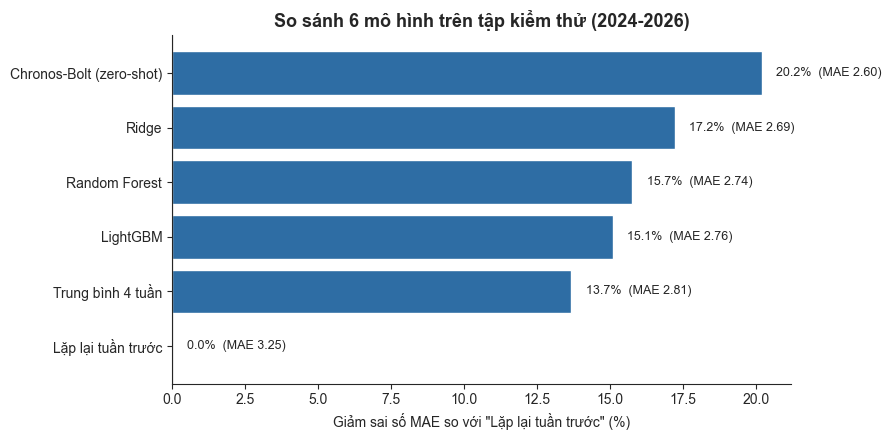

In [8]:
# Biểu đồ: mức cải thiện MAE so với mốc "Lặp lại tuần trước" (càng dài càng tốt)
r = results.sort_values("cai_thien_so_voi_lap_lai_%")
plt.figure(figsize=(9, 4.5))
plt.barh(r["mo_hinh"], r["cai_thien_so_voi_lap_lai_%"], color=MAU)
plt.axvline(0, color="black", linewidth=0.8)
for y, (v, mae) in enumerate(zip(r["cai_thien_so_voi_lap_lai_%"], r["MAE"])):
    plt.text(v + (0.5 if v >= 0 else -0.5), y, f"{v:.1f}%  (MAE {mae:.2f})",
             va="center", ha="left" if v >= 0 else "right", fontsize=9)
sns.despine()
plt.xlabel('Giảm sai số MAE so với "Lặp lại tuần trước" (%)')
plt.ylabel("")
plt.title("So sánh 6 mô hình trên tập kiểm thử (2024-2026)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_m01_model_comparison.png", dpi=300)
plt.show()

In [9]:
# Kiểm định Wilcoxon: so sánh sai số trung bình MỖI TUẦN giữa các cặp mô hình (mỗi tuần là một quan sát)
for m in MODELS:
    test[f"err_{m}"] = (test[TARGET] - test[f"pred_{m}"]).abs()
weekly_err = test.groupby("week_start")[[f"err_{m}" for m in MODELS]].mean()

best, second = results["mo_hinh"].iloc[0], results["mo_hinh"].iloc[1]
for a, b in [(best, second), (best, "Lặp lại tuần trước")]:
    stat, p = wilcoxon(weekly_err[f"err_{a}"], weekly_err[f"err_{b}"])
    ty_le = (weekly_err[f"err_{a}"] < weekly_err[f"err_{b}"]).mean() * 100
    print(f"{a} so với {b}: tốt hơn ở {ty_le:.1f}% số tuần, Wilcoxon p-value = {p:.4f}")

Chronos-Bolt (zero-shot) so với Ridge: tốt hơn ở 63.9% số tuần, Wilcoxon p-value = 0.0000
Chronos-Bolt (zero-shot) so với Lặp lại tuần trước: tốt hơn ở 92.4% số tuần, Wilcoxon p-value = 0.0000


**Nhận xét:** So sánh 6 mô hình

**Vì sao làm bước này?** Tất cả mô hình được đánh giá trên **cùng một tập kiểm thử** (144 tuần, 2024–2026, dữ liệu mô hình chưa từng thấy). Biểu đồ dùng **mức cải thiện so với mốc đơn giản nhất** để thấy rõ chênh lệch; kiểm định Wilcoxon theo từng tuần cho biết chênh lệch có ý nghĩa thống kê hay chỉ do ngẫu nhiên.

**Kết quả cần đọc:**
- **Chronos-Bolt (zero-shot) tốt nhất**: MAE **2.60**, giảm **20.2%** sai số so với "Lặp lại tuần trước" — dù **không được huấn luyện lại** và **chỉ dùng lịch sử số yêu cầu**.
- Chronos tốt hơn Ridge (thứ 2, MAE **2.69**) ở **63.9%** số tuần, và tốt hơn "Lặp lại tuần trước" ở **92.4%** số tuần; cả hai khác biệt đều **có ý nghĩa thống kê** (p < 0.0001).
- Mốc **"Trung bình 4 tuần"** (MAE **2.81**) rất khó vượt: các mô hình học máy chỉ tốt hơn nó **1.6–4.1%**; xét theo RMSE, Random Forest và LightGBM còn **kém hơn** mốc này → mô hình cây dự báo sai nhiều ở các tuần đột biến.
- Kết quả **ổn định** giữa các seed (độ lệch chưa tới 0.5% MAE).
- → Với bài toán này, **lịch sử nhu cầu gần đây là thông tin quan trọng nhất**; mô hình nền học sẵn từ rất nhiều chuỗi thời gian khai thác thông tin đó tốt hơn các mô hình huấn luyện riêng, phù hợp với kết quả ở Notebook 4 (thời tiết và giấy phép chỉ liên quan yếu).

## **4. Kiểm tra khả năng tổng quát hoá — RQ2**

In [10]:
# (a) Nhiều mốc thời gian: lặp lại việc chia huấn luyện/kiểm thử ở 5 mốc, mỗi lần kiểm thử 26 tuần
cutoffs = ["2022-01-03", "2022-07-04", "2023-01-02", "2023-07-03", "2024-01-01"]
roll_rows = []
for c in cutoffs:
    cut = pd.Timestamp(c)
    tr = feat[feat["week_start"] < cut - pd.Timedelta(days=7)]
    te = feat[(feat["week_start"] >= cut) & (feat["week_start"] < cut + pd.Timedelta(weeks=26))]
    row = {"moc_kiem_thu": c,
           "Lặp lại tuần trước": mean_absolute_error(te[TARGET], te["n"]),
           "Trung bình 4 tuần": mean_absolute_error(te[TARGET], te["n_ma4"])}
    for name in ["Ridge", "LightGBM"]:
        pred, _ = fit_predict(name, tr, te)
        row[name] = mean_absolute_error(te[TARGET], pred)
    roll_rows.append(row)

rolling_df = pd.DataFrame(roll_rows).round(3)
rolling_df

,moc_kiem_thu,Lặp lại tuần trước,Trung bình 4 tuần,Ridge,LightGBM
0,2022-01-03,2.533,2.096,1.981,2.042
1,2022-07-04,2.144,1.957,2.034,2.080
2,2023-01-02,3.921,3.500,3.005,2.982
3,2023-07-03,2.672,2.279,2.083,2.029
4,2024-01-01,2.984,2.962,2.440,2.390


**Nhận xét:** Kiểm tra ở nhiều mốc thời gian

**Vì sao làm bước này?** Kết quả ở mục 3 chỉ dựa trên một lần chia dữ liệu. Lặp lại việc huấn luyện và kiểm thử ở **5 mốc thời gian** (mỗi lần kiểm thử 26 tuần) giúp kiểm tra xem thứ hạng các mô hình có ổn định hay chỉ đúng với một giai đoạn. (Chronos không chạy lại ở đây vì tốn thời gian; so sánh với 2 mốc đơn giản và 2 mô hình học máy.)

**Kết quả cần đọc:**
- Ridge và LightGBM **luôn tốt hơn "Lặp lại tuần trước"** ở cả 5 mốc.
- So với **"Trung bình 4 tuần"**, học máy thắng ở **4/5 mốc**; riêng giai đoạn **nửa cuối 2022** (ít biến động) thì mốc đơn giản này lại tốt nhất.
- Học máy có lợi thế rõ nhất ở các giai đoạn **nhiều biến động**, ví dụ nửa đầu 2023 (có bão tháng 3/2023): MAE **2.98–3.01** so với **3.50** của trung bình 4 tuần.
- Mô hình học máy tốt nhất **thay đổi theo giai đoạn** (Ridge ở mốc đầu, LightGBM ở 3 mốc gần đây) → không có mô hình học máy nào luôn vượt trội.

In [11]:
# (b) Khu phố mới: giữ lại từng nhóm khu phố, huấn luyện trên các khu phố còn lại rồi dự báo cho nhóm được giữ lại.
# Không dùng mã khu phố (khu phố "mới" chưa có mã), nhưng vẫn dùng lịch sử nhu cầu của chính khu phố đó.
cols_lno = [c for c in FEATURES if c != "nbhd_code"]
nbhds = np.array(sorted(feat["nbhd"].unique()))
folds = np.array_split(np.random.default_rng(42).permutation(nbhds), 5)

ref_pred, _ = fit_predict("LightGBM", train, test, cols=cols_lno)    # mô hình đã thấy mọi khu phố
test["pred_ref_lno"] = ref_pred

lno_rows = []
for k, hold in enumerate(folds, start=1):
    tr = train[~train["nbhd"].isin(hold)]
    te = test[test["nbhd"].isin(hold)]
    pred, _ = fit_predict("LightGBM", tr, te, cols=cols_lno)
    lno_rows.append({
        "nhom": k, "so_khu_pho": len(hold),
        "MAE_lap_lai_tuan_truoc": mean_absolute_error(te[TARGET], te["n"]),
        "MAE_da_thay_khu_pho": mean_absolute_error(te[TARGET], te["pred_ref_lno"]),
        "MAE_chua_thay_khu_pho": mean_absolute_error(te[TARGET], pred),
        "cac_khu_pho": ", ".join(sorted(hold)),
    })

lno_df = pd.DataFrame(lno_rows)
lno_df["tang_sai_so_%"] = (lno_df["MAE_chua_thay_khu_pho"] / lno_df["MAE_da_thay_khu_pho"] - 1) * 100
print(f"Mức tăng sai số trung bình khi gặp khu phố chưa thấy: {lno_df['tang_sai_so_%'].mean():+.1f}%")
lno_df.drop(columns="cac_khu_pho").round(3)

Mức tăng sai số trung bình khi gặp khu phố chưa thấy: +9.7%


,nhom,so_khu_pho,MAE_lap_lai_tuan_truoc,MAE_da_thay_khu_pho,MAE_chua_thay_khu_pho,tang_sai_so_%
0,1,9,3.621,2.952,3.349,13.440
1,2,8,3.367,3.007,3.460,15.077
2,3,8,3.033,2.497,2.688,7.647
3,4,8,2.677,2.282,2.262,-0.870
4,5,8,3.532,2.982,3.369,12.988


**Nhận xét:** Tổng quát hoá sang khu phố mới

**Vì sao làm bước này?** Chia 41 khu phố thành 5 nhóm; mỗi lần giữ lại một nhóm, huấn luyện LightGBM trên các khu phố còn lại rồi dự báo cho nhóm bị giữ lại, so với mô hình đã được huấn luyện cả trên những khu phố đó. Mô hình vẫn dùng **lịch sử nhu cầu của chính khu phố mới** — đây là tình huống mở rộng mô hình sang khu phố chưa có trong dữ liệu huấn luyện.

**Kết quả cần đọc:**
- Khi gặp khu phố chưa thấy, sai số tăng trung bình **9.8%**, nhưng rất khác nhau giữa các nhóm: từ **gần như không đổi** (nhóm 4, −1.0%) đến **+18.6%** (nhóm 1).
- Sai số tăng mạnh nhất ở các nhóm có khu phố **đặc biệt**: nhóm 1 có **Mission** (tổng nhu cầu cao nhất, +18.6%), nhóm 2 có **Tenderloin** (cao nhất tính trên 1.000 cây, +16.4%), nhóm 5 có **West of Twin Peaks** (+11.4%).
- Nhóm 4 (có Bayview Hunters Point, Sunset/Parkside — nhiều yêu cầu nhưng do nhiều cây) gần như **không mất độ chính xác**.
- Ở 4/5 nhóm, mô hình vẫn tốt hơn "Lặp lại tuần trước"; riêng **nhóm 2** thì kém hơn (3.51 so với 3.37).
- → Mô hình **mở rộng được** sang khu phố có mức nhu cầu "bình thường", nhưng với các khu phố **có mức nhu cầu khác hẳn** phần còn lại thì cần huấn luyện có dữ liệu của chính khu đó.

## **5. Độ tin cậy vận hành: khoảng dự báo và cảnh báo — trả lời RQ4**

In [12]:
# Chọn mô hình học máy tốt nhất ở mục 3 (Ridge / Random Forest / LightGBM) để xây dựng khoảng dự báo và cảnh báo
ml_results = results[results["mo_hinh"].isin(["Ridge", "Random Forest", "LightGBM"])]
BEST_ML = ml_results.sort_values("MAE")["mo_hinh"].iloc[0]
print("Mô hình học máy tốt nhất:", BEST_ML)

# Khoảng dự báo 90% bằng phương pháp conformal:
#  - huấn luyện trên dữ liệu trước 07/2023, dùng 26 tuần cuối năm 2023 (hiệu chuẩn) để đo sai số thực tế
#  - độ rộng khoảng tỷ lệ với mức nhu cầu gần đây của khu phố (n_ma4 + 1): khu nhiều yêu cầu -> khoảng rộng hơn
ALPHA = 0.10
CAL_START = pd.Timestamp("2023-07-03")
fit_set = train[train["week_start"] < CAL_START - pd.Timedelta(days=7)]
cal_set = train[train["week_start"] >= CAL_START]

_, model_ci = fit_predict(BEST_ML, fit_set, cal_set)
cal_pred = np.clip(model_ci.predict(cal_set[FEATURES]), 0, None)
scores = np.abs(cal_set[TARGET] - cal_pred) / (cal_set["n_ma4"] + 1)
level = min(1.0, np.ceil((len(scores) + 1) * (1 - ALPHA)) / len(scores))
q_hat = np.quantile(scores, level)

test["ci_pred"] = np.clip(model_ci.predict(test[FEATURES]), 0, None)
test["ci_lower"] = np.clip(test["ci_pred"] - q_hat * (test["n_ma4"] + 1), 0, None)
test["ci_upper"] = test["ci_pred"] + q_hat * (test["n_ma4"] + 1)
test["trong_khoang"] = (test[TARGET] >= test["ci_lower"]) & (test[TARGET] <= test["ci_upper"])

cov_nb = test.groupby("nbhd")["trong_khoang"].mean()
print(f"\nMục tiêu bao phủ           : {(1 - ALPHA) * 100:.0f}%")
print(f"Bao phủ thực tế (toàn bộ)  : {test['trong_khoang'].mean() * 100:.1f}%")
print(f"Khu phố bao phủ thấp nhất  : {cov_nb.min() * 100:.1f}% ({cov_nb.idxmin()})")
print(f"Số khu phố đạt từ 85%      : {(cov_nb >= 0.85).sum()}/{len(cov_nb)}")
print(f"Độ rộng khoảng trung bình  : {(test['ci_upper'] - test['ci_lower']).mean():.1f} yêu cầu")
print("\nBao phủ theo năm:")
print((test.groupby(test["week_start"].dt.year)["trong_khoang"].mean() * 100).round(1).to_string())

Mô hình học máy tốt nhất: Ridge

Mục tiêu bao phủ           : 90%
Bao phủ thực tế (toàn bộ)  : 89.1%
Khu phố bao phủ thấp nhất  : 81.9% (Golden Gate Park)
Số khu phố đạt từ 85%      : 34/41
Độ rộng khoảng trung bình  : 11.2 yêu cầu

Bao phủ theo năm:
week_start
2024    89.0
2025    88.0
2026    90.7


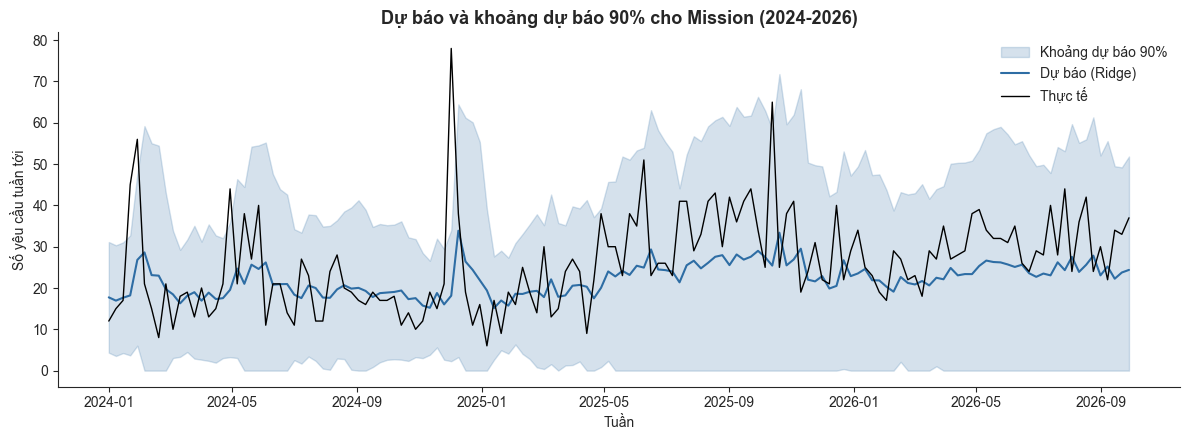

In [13]:
# Minh hoạ khoảng dự báo cho Mission (khu phố có nhu cầu cao nhất)
m = test[test["nbhd"] == "Mission"].sort_values("week_start")
plt.figure(figsize=(12, 4.5))
plt.fill_between(m["week_start"], m["ci_lower"], m["ci_upper"], color=MAU, alpha=0.2, label="Khoảng dự báo 90%")
plt.plot(m["week_start"], m["ci_pred"], color=MAU, linewidth=1.5, label=f"Dự báo ({BEST_ML})")
plt.plot(m["week_start"], m[TARGET], color="black", linewidth=1, label="Thực tế")
sns.despine()
plt.xlabel("Tuần")
plt.ylabel("Số yêu cầu tuần tới")
plt.title("Dự báo và khoảng dự báo 90% cho Mission (2024-2026)", fontsize=13, fontweight="bold")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_m02_prediction_interval_mission.png", dpi=300)
plt.show()

**Nhận xét:** Khoảng dự báo 90%

**Vì sao làm bước này?** Một con số dự báo đơn lẻ không cho biết nó có thể sai bao nhiêu. Khoảng dự báo 90% cho đội bảo trì biết nhu cầu tuần tới **có thể dao động trong khoảng nào**. Phương pháp conformal đo sai số thực tế của mô hình (Ridge) trên 26 tuần cuối 2023, rồi đặt độ rộng khoảng **tỷ lệ với mức nhu cầu gần đây** của từng khu phố. Biểu đồ minh hoạ cho Mission — khu phố có nhu cầu cao nhất.

**Kết quả cần đọc:**
- Khoảng dự báo chứa đúng giá trị thực ở **89.2%** số trường hợp — rất sát mục tiêu **90%**, và **ổn định qua các năm** (2024: 89.0%, 2025: 88.0%, 2026: 90.8%).
- **35/41** khu phố đạt từ 85% trở lên; thấp nhất là **Golden Gate Park (81.9%)** — khu công viên, nhu cầu thất thường. Độ rộng khoảng trung bình **11.2 yêu cầu**.
- Ở Mission, đường dự báo **trơn và đi sau thực tế**: các tuần đột biến (như khoảng 78 yêu cầu cuối 2024) không đoán trước được, mô hình chỉ tăng theo vào tuần kế tiếp.
- Từ **giữa 2025**, dự báo của Mission **thấp hơn thực tế** khá đều (khoảng 25 so với 25–45) — dấu hiệu mô hình chưa theo kịp xu hướng tăng (kiểm tra ở mục 7).
- → Khoảng dự báo **đáng tin cậy** cho việc lập kế hoạch; riêng các tuần đột biến vẫn là phần mô hình chưa dự báo được.

In [14]:
# Cảnh báo "tuần nguy cơ cao": tuần tới vượt mức 90% cao nhất của chính khu phố đó trong 52 tuần gần nhất
# (ngưỡng chỉ dùng dữ liệu đã biết đến tuần hiện tại, và tự cập nhật theo xu hướng tăng của nhu cầu)
feat_all["nguong_cao"] = feat_all.groupby("nbhd")["n"].transform(lambda s: s.rolling(52).quantile(0.9))
test = test.drop(columns="nguong_cao", errors="ignore").merge(
    feat_all[["nbhd", "week_start", "nguong_cao"]], on=["nbhd", "week_start"], how="left")

test["thuc_te_cao"] = test[TARGET] > test["nguong_cao"]

def alert_metrics(name, canh_bao):
    tp = (canh_bao & test["thuc_te_cao"]).sum()
    fp = (canh_bao & ~test["thuc_te_cao"]).sum()
    fn = (~canh_bao & test["thuc_te_cao"]).sum()
    tn = (~canh_bao & ~test["thuc_te_cao"]).sum()
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    return {"cach_canh_bao": name,
            "do_chinh_xac (precision)": precision,
            "do_nhay (recall)": recall,
            "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0,
            "ty_le_bao_dong_gia": fp / (fp + tn)}

alert_df = pd.DataFrame([
    alert_metrics("Dự báo vượt ngưỡng", test["ci_pred"] > test["nguong_cao"]),
    alert_metrics("Cận trên khoảng dự báo vượt ngưỡng", test["ci_upper"] > test["nguong_cao"]),
]).round(3)

print(f"Tỷ lệ tuần nguy cơ cao thực tế trong tập kiểm thử: {test['thuc_te_cao'].mean() * 100:.1f}%")
alert_df

Tỷ lệ tuần nguy cơ cao thực tế trong tập kiểm thử: 13.0%


,cach_canh_bao,do_chinh_xac (precision),do_nhay (recall),F1,ty_le_bao_dong_gia
0,Dự báo vượt ngưỡng,0.259,0.065,0.104,0.028
1,Cận trên khoảng dự báo vượt ngưỡng,0.154,0.822,0.260,0.673


**Nhận xét:** Cảnh báo tuần nguy cơ cao

**Vì sao làm bước này?** Đội bảo trì cần biết trước **tuần nào sẽ quá tải** ở khu phố nào. Một tuần được coi là nguy cơ cao nếu số yêu cầu vượt mức 90% cao nhất của chính khu phố đó trong 52 tuần gần nhất (thực tế chiếm **13.0%** số tuần kiểm thử). So sánh 2 cách cảnh báo: dựa vào **giá trị dự báo** và dựa vào **cận trên của khoảng dự báo**.

**Kết quả cần đọc:**
- **Dựa vào giá trị dự báo:** rất ít báo động giả (**2.8%**) nhưng chỉ bắt được **6.5%** số tuần nguy cơ cao — vì dự báo trơn, gần như không bao giờ vọt lên đủ cao.
- **Dựa vào cận trên:** bắt được **82.2%** số tuần nguy cơ cao nhưng báo động giả tới **67.4%**; trong các lần cảnh báo chỉ **15.4%** là đúng — gần bằng tỷ lệ ngẫu nhiên (13.0%).
- → **Chưa thể cảnh báo sớm tuần quá tải một cách đáng tin cậy**: các đột biến chủ yếu do **bão**, mà mô hình chỉ biết dữ liệu đến hết tuần hiện tại. Muốn cảnh báo tốt cần thêm thông tin **nhìn trước** như dự báo thời tiết hoặc cảnh báo bão (hướng phát triển).

## **6. Những yếu tố nào thực sự đóng góp vào dự báo — trả lời RQ2**

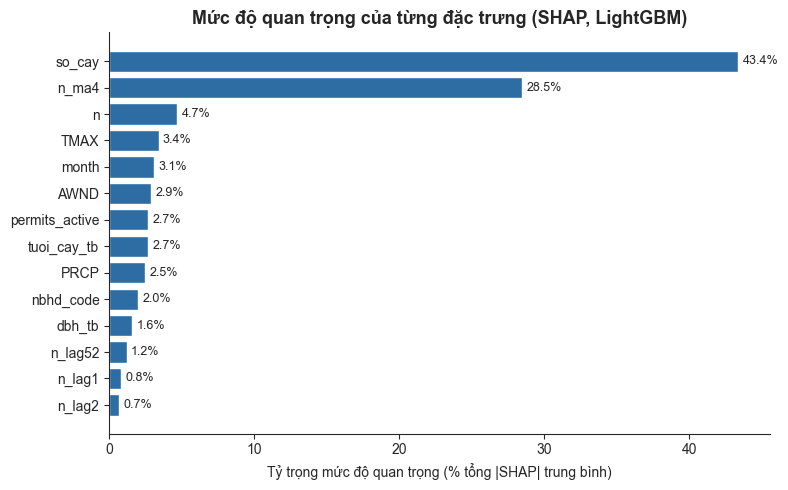

In [15]:
import shap

# SHAP cần mô hình dạng cây nên dùng LightGBM (seed 0, huấn luyện trên toàn bộ tập huấn luyện)
_, lgb_model = fit_predict("LightGBM", train, test)
X_s = test[FEATURES].sample(min(3000, len(test)), random_state=0)
shap_values = shap.TreeExplainer(lgb_model).shap_values(X_s)

imp = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES)
shap_share = (imp / imp.sum() * 100).sort_values(ascending=False).round(1)

plt.figure(figsize=(8, 5))
s = shap_share.sort_values()
plt.barh(s.index, s.values, color=MAU)
for y, v in enumerate(s.values):
    plt.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=9)
sns.despine()
plt.xlabel("Tỷ trọng mức độ quan trọng (% tổng |SHAP| trung bình)")
plt.title("Mức độ quan trọng của từng đặc trưng (SHAP, LightGBM)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_m03_shap_importance.png", dpi=300)
plt.show()

In [16]:
# Thử bỏ từng nhóm đặc trưng, huấn luyện lại LightGBM (3 seed) và đo MAE trên tập kiểm thử
abl_rows = []
for nhom, cols in [("Đầy đủ đặc trưng", [])] + list(NHOM_DAC_TRUNG.items()):
    keep = [c for c in FEATURES if c not in cols]
    maes = [mean_absolute_error(test[TARGET], fit_predict("LightGBM", train, test, cols=keep, seed=s)[0])
            for s in SEEDS]
    abl_rows.append({"bo_nhom": nhom, "MAE": np.mean(maes), "do_lech_chuan": np.std(maes)})

ablation_df = pd.DataFrame(abl_rows)
mae_full = ablation_df.loc[0, "MAE"]
ablation_df["thay_doi_MAE_%"] = (ablation_df["MAE"] / mae_full - 1) * 100
ablation_df["shap_%"] = ablation_df["bo_nhom"].map(
    {nhom: shap_share[cols].sum() for nhom, cols in NHOM_DAC_TRUNG.items()})
ablation_df.round(3)

,bo_nhom,MAE,do_lech_chuan,thay_doi_MAE_%,shap_%
0,Đầy đủ đặc trưng,2.768,0.007,0.000,NaN
1,Lịch sử nhu cầu,3.143,0.004,13.551,35.9
2,Giấy phép thi công,2.763,0.007,-0.204,2.7
3,Thời tiết,2.768,0.003,-0.020,8.8
4,Đặc điểm cây,2.695,0.002,-2.661,47.7
5,Lịch (tháng),2.752,0.009,-0.585,3.1
6,Khu phố,2.755,0.005,-0.480,2.0


**Nhận xét:** Những yếu tố thực sự đóng góp vào dự báo

**Vì sao làm bước này?** Dùng 2 cách bổ sung cho nhau: **SHAP** cho biết mô hình **dựa vào** đặc trưng nào nhiều nhất, còn **thử bỏ từng nhóm đặc trưng** (huấn luyện lại LightGBM, 3 seed) cho biết nhóm đó có **thật sự làm dự báo chính xác hơn** hay không. Thay đổi MAE dưới khoảng 0.5% nằm trong mức dao động ngẫu nhiên giữa các seed.

**Kết quả cần đọc:**
- **Lịch sử nhu cầu là nhóm duy nhất thật sự cần thiết**: bỏ đi thì sai số tăng **13.5%**; trong đó **trung bình 4 tuần** là đặc trưng quan trọng nhất (27.5% SHAP).
- **Thời tiết và giấy phép thi công không đóng góp gì**: bỏ đi MAE gần như không đổi (+0.01% và +0.06%) — khớp với Notebook 4 (tương quan yếu, giấy phép chỉ phản ánh khu phố đông đúc).
- **Đặc điểm cây** được SHAP xếp cao nhất (**49.3%**, riêng số cây 44.5%) nhưng **bỏ đi lại giảm sai số 2.7%**: số cây cố định theo khu phố nên mô hình dùng nó để "nhớ" mức nhu cầu cũ của từng khu — mức này **lỗi thời** khi nhu cầu tăng mạnh từ 2025.
- → **Mức độ quan trọng theo SHAP không đồng nghĩa với đóng góp thực sự**. Yếu tố quyết định là **nhu cầu gần đây** — giải thích vì sao **Chronos-Bolt**, chỉ dùng lịch sử nhu cầu, lại dự báo tốt nhất.

## **7. Tái huấn luyện định kỳ — trả lời RQ3**

In [17]:
# So sánh: mô hình cố định (huấn luyện một lần đến hết 2023) và mô hình tái huấn luyện mỗi 4 tuần
# (mỗi lần dùng mọi dữ liệu đã biết đến thời điểm đó)
test["pred_co_dinh"] = test[f"pred_{BEST_ML}"]
test["pred_tai_huan_luyen"] = np.nan

weeks = sorted(test["week_start"].unique())
for i in range(0, len(weeks), 4):
    start = pd.Timestamp(weeks[i])
    block = test["week_start"].isin(weeks[i:i + 4])
    tr = feat[feat["week_start"] < start - pd.Timedelta(days=7)]
    pred, _ = fit_predict(BEST_ML, tr, test[block])
    test.loc[block, "pred_tai_huan_luyen"] = pred

rq5_rows = []
for col, ten in [("pred_Lặp lại tuần trước", "Lặp lại tuần trước"),
                 ("pred_co_dinh", f"{BEST_ML} cố định"),
                 ("pred_tai_huan_luyen", f"{BEST_ML} tái huấn luyện mỗi 4 tuần")]:
    rq5_rows.append({"mo_hinh": ten,
                     "MAE": mean_absolute_error(test[TARGET], test[col]),
                     "sai_lech_tb (du_bao - thuc_te)": (test[col] - test[TARGET]).mean()})
rq5_df = pd.DataFrame(rq5_rows).round(3)

err_fixed = test.assign(e=(test[TARGET] - test["pred_co_dinh"]).abs()).groupby("week_start")["e"].mean()
err_retrain = test.assign(e=(test[TARGET] - test["pred_tai_huan_luyen"]).abs()).groupby("week_start")["e"].mean()
stat, p_rq5 = wilcoxon(err_fixed, err_retrain)
print(f"Tái huấn luyện tốt hơn ở {(err_retrain < err_fixed).mean() * 100:.1f}% số tuần, Wilcoxon p-value = {p_rq5:.4f}")
rq5_df

Tái huấn luyện tốt hơn ở 64.6% số tuần, Wilcoxon p-value = 0.0000


,mo_hinh,MAE,sai_lech_tb (du_bao - thuc_te)
0,Lặp lại tuần trước,3.255,-0.037
1,Ridge cố định,2.695,-1.191
2,Ridge tái huấn luyện mỗi 4 tuần,2.643,-0.997


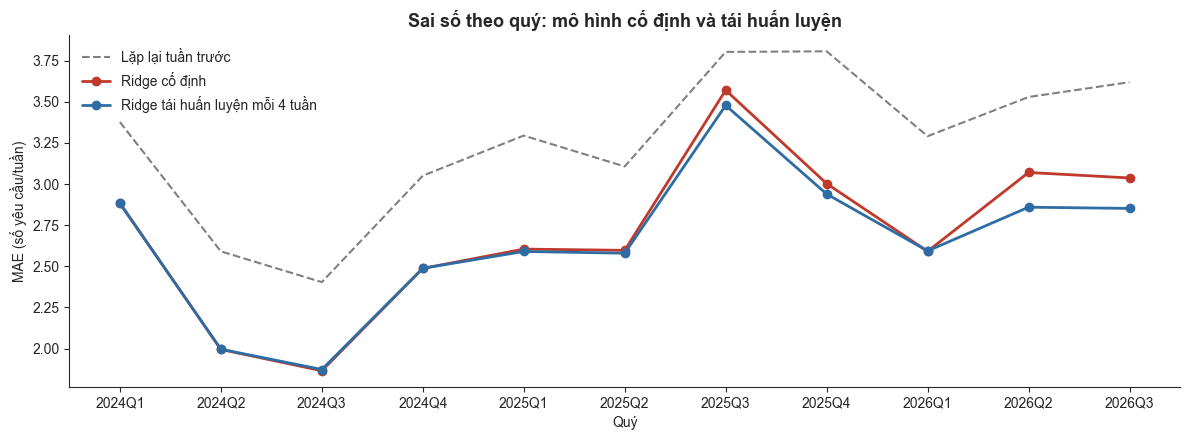

In [18]:
# MAE theo quý: mô hình cố định và tái huấn luyện
q = test.assign(quy=test["week_start"].dt.to_period("Q").astype(str))
mae_q = q.groupby("quy").apply(lambda g: pd.Series({
    "Lặp lại tuần trước": mean_absolute_error(g[TARGET], g["pred_Lặp lại tuần trước"]),
    "Cố định": mean_absolute_error(g[TARGET], g["pred_co_dinh"]),
    "Tái huấn luyện mỗi 4 tuần": mean_absolute_error(g[TARGET], g["pred_tai_huan_luyen"]),
}))

plt.figure(figsize=(12, 4.5))
plt.plot(mae_q.index, mae_q["Lặp lại tuần trước"], color="gray", linestyle="--", linewidth=1.5, label="Lặp lại tuần trước")
plt.plot(mae_q.index, mae_q["Cố định"], color="#C0392B", marker="o", linewidth=2, label=f"{BEST_ML} cố định")
plt.plot(mae_q.index, mae_q["Tái huấn luyện mỗi 4 tuần"], color=MAU, marker="o", linewidth=2,
         label=f"{BEST_ML} tái huấn luyện mỗi 4 tuần")
sns.despine()
plt.xlabel("Quý")
plt.ylabel("MAE (số yêu cầu/tuần)")
plt.title("Sai số theo quý: mô hình cố định và tái huấn luyện", fontsize=13, fontweight="bold")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_m04_retrain_by_quarter.png", dpi=300)
plt.show()

**Nhận xét:** Tái huấn luyện định kỳ

**Vì sao làm bước này?** Notebook 3 và 4 cho thấy nhu cầu **tăng mạnh từ 2025**. Mô hình học từ dữ liệu cũ có thể dự báo thấp hơn thực tế khi điều kiện thay đổi. So sánh Ridge **cố định** (huấn luyện một lần đến hết 2023) với Ridge **cập nhật mỗi 4 tuần** — cả về MAE và **sai lệch trung bình** (âm = dự báo thấp hơn thực tế), kèm kiểm định Wilcoxon theo từng tuần.

**Kết quả cần đọc:**
- Tái huấn luyện giảm MAE từ **2.695 xuống 2.643** (**−1.9%**), tốt hơn ở **64.6%** số tuần; khác biệt **có ý nghĩa thống kê** (p < 0.0001).
- Lợi ích **không đều theo thời gian**: năm 2024 đến quý 2/2025 hai mô hình gần như trùng nhau; từ **quý 3/2025** — khi nhu cầu bắt đầu tăng mạnh — khoảng cách mở rộng, lớn nhất ở **quý 2–3/2026** (giảm khoảng **6–7%** sai số).
- Cả hai đều **dự báo thấp hơn thực tế** (sai lệch **−1.19** và **−1.00** yêu cầu/tuần/khu phố); tái huấn luyện chỉ thu hẹp được một phần.
- → Tái huấn luyện định kỳ **giúp mô hình thích ứng khi nhu cầu thay đổi**, đặc biệt trong giai đoạn tăng trưởng; khi nhu cầu ổn định thì gần như không cần thiết.

## **8. Xuất bảng kết quả**

In [19]:
results.to_csv("../Outputs/tables/model_01_comparison.csv", index=False)
seed_df.to_csv("../Outputs/tables/model_02_seed_stability.csv", index=False)
rolling_df.to_csv("../Outputs/tables/model_03_rolling_origin.csv", index=False)
lno_df.to_csv("../Outputs/tables/model_04_new_neighbourhoods.csv", index=False)
cov_nb.rename("bao_phu").to_csv("../Outputs/tables/model_05_interval_coverage_by_nbhd.csv")
alert_df.to_csv("../Outputs/tables/model_06_alerts.csv", index=False)
ablation_df.to_csv("../Outputs/tables/model_07_ablation_shap.csv", index=False)
rq5_df.to_csv("../Outputs/tables/model_08_retrain.csv", index=False)
test.to_csv("../Data/processed/SF_Tree_Test_Predictions.csv", index=False)

print("Đã lưu xong 4 biểu đồ, 8 bảng kết quả và bảng dự báo trên tập kiểm thử.")

Đã lưu xong 4 biểu đồ, 8 bảng kết quả và bảng dự báo trên tập kiểm thử.
